In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import auc

In [2]:
dico_hallmarks_ids = {
    "01": "TISSUE_INVASION_METASTASIS",
    "02": "REPROGRAMMING_ENERGY_METABOLISM",
    "03": "REPLICATIVE_IMMORTALITY",
    "04": "GENOME_INSTABILITY",
    "05": "RESISTING_CELL_DEATH",
    "06": "EVADING_GROWTH_SUPPRESSORS",
    "07": "EVADING_IMMUNE_DESTRUCTION",
    "08": "SUSTAINED_ANGIOGENESIS",
    "09": "SUSTAINING_PROLIFERATIVE_SIGNALING",
    "10": "TUMOR_PROMOTING_INFLAMMATION"
}

# dico_hallmarks_ids = {
#     "01": "TISSUE_INVASION_METASTASIS"
# }

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


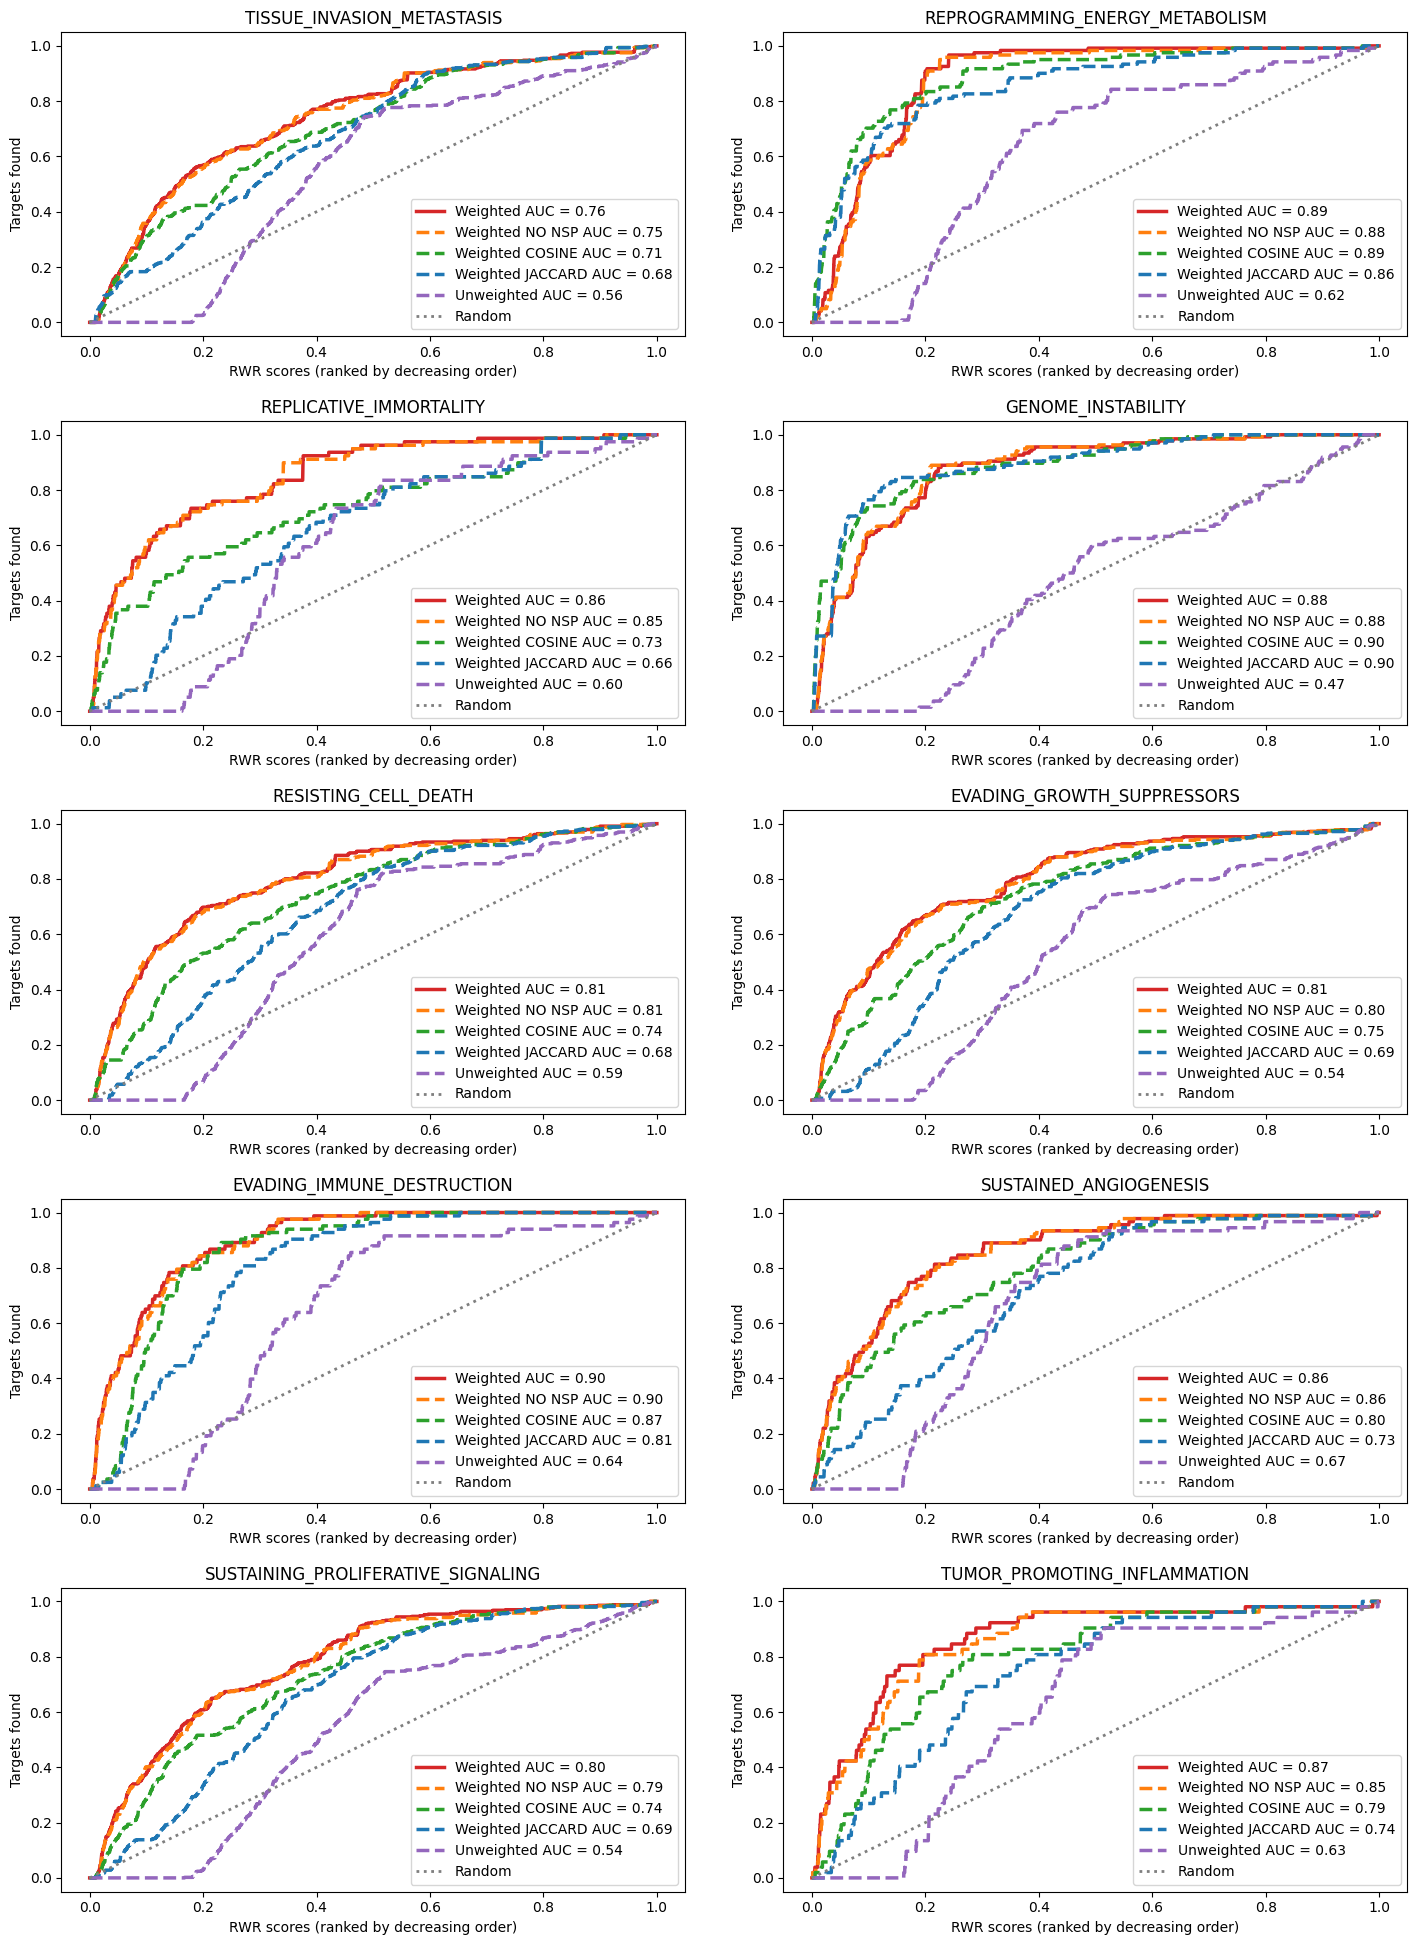

In [3]:
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(15, 20))
plt.tight_layout(pad=4.0)

for i, (hallmark_id, hallmark_name) in enumerate(dico_hallmarks_ids.items()):
    row = i // 2 
    col = i % 2

    # --- UNWEIGHTED ---
    seeds_file_unweighted = f"Configs/ReactomeUNWEIGHTED/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_unweighted = f"Configs/ReactomeUNWEIGHTED/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_unweighted = f"../../Results/ValidationRWROutput/ReactomeUNWEIGHTED/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_unweighted = pd.read_csv(scores_file_unweighted, sep='\t')
    with open(seeds_file_unweighted, 'r') as f:
        seeds_unweighted = set(line.strip() for line in f if line.strip())
    with open(targets_file_unweighted, 'r') as f:
        targets_unweighted = set(line.strip() for line in f if line.strip())
    df_scores_unweighted['is_target'] = df_scores_unweighted['node'].isin(targets_unweighted).astype(int)
    df_scores_unweighted['is_seed'] = df_scores_unweighted['node'].isin(seeds_unweighted).astype(int)
    df_scores_unweighted = df_scores_unweighted.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets_unweighted = df_scores_unweighted['is_target'].sum()
    n_total_unweighted = len(df_scores_unweighted)
    n_non_targets_unweighted = n_total_unweighted - n_targets_unweighted
    cumulative_targets_unweighted = np.cumsum(df_scores_unweighted['is_target'].values)
    cumulative_non_targets_unweighted = np.cumsum((1 - df_scores_unweighted['is_target']).values)
    positions_unweighted = np.arange(len(df_scores_unweighted)) + 1
    positions_fraction_unweighted = positions_unweighted / len(df_scores_unweighted)
    tpr_unweighted = cumulative_targets_unweighted / n_targets_unweighted
    fpr_unweighted = cumulative_non_targets_unweighted / n_non_targets_unweighted
    auc_score_unweighted = auc(fpr_unweighted, tpr_unweighted)

    # WEIGHTED WITHOUT NSP
    seeds_file_weighted_no_nsp = f"Configs/ReactomeWEIGHTED_NO_NSP/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_weighted_no_nsp = f"Configs/ReactomeWEIGHTED_NO_NSP/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_weighted_no_nsp = f"../../Results/ValidationRWROutput/ReactomeWEIGHTED_NO_NSP/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_weighted_no_nsp = pd.read_csv(scores_file_weighted_no_nsp, sep='\t')
    with open(seeds_file_weighted_no_nsp, 'r') as f:
        seeds_no_nsp = set(line.strip() for line in f if line.strip())
    with open(targets_file_weighted_no_nsp, 'r') as f:
        targets_no_nsp = set(line.strip() for line in f if line.strip())
    df_scores_weighted_no_nsp['is_target'] = df_scores_weighted_no_nsp['node'].isin(targets_no_nsp).astype(int)
    df_scores_weighted_no_nsp['is_seed'] = df_scores_weighted_no_nsp['node'].isin(seeds_no_nsp).astype(int)
    df_scores_weighted_no_nsp = df_scores_weighted_no_nsp.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets_no_nsp = df_scores_weighted_no_nsp['is_target'].sum()
    n_total_no_nsp = len(df_scores_weighted_no_nsp)
    n_non_targets_no_nsp = n_total_no_nsp - n_targets_no_nsp
    cumulative_targets_no_nsp = np.cumsum(df_scores_weighted_no_nsp['is_target'].values)
    cumulative_non_targets_no_nsp = np.cumsum((1 - df_scores_weighted_no_nsp['is_target']).values)
    positions_no_nsp = np.arange(len(df_scores_weighted_no_nsp)) + 1
    positions_fraction_no_nsp = positions_no_nsp / len(df_scores_weighted_no_nsp)
    tpr_weighted_no_nsp = cumulative_targets_no_nsp / n_targets_no_nsp
    fpr_weighted_no_nsp = cumulative_non_targets_no_nsp / n_non_targets_no_nsp
    auc_score_weighted_no_nsp = auc(fpr_weighted_no_nsp, tpr_weighted_no_nsp)

    # WEIGHTED COSINE
    seeds_file_weighted_cosine = f"Configs/ReactomeWEIGHTED_COSINE/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_weighted_cosine = f"Configs/ReactomeWEIGHTED_COSINE/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_weighted_cosine = f"../../Results/ValidationRWROutput/ReactomeWEIGHTED_COSINE/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_weighted_cosine = pd.read_csv(scores_file_weighted_cosine, sep='\t')
    with open(seeds_file_weighted_cosine, 'r') as f:
        seeds_cosine = set(line.strip() for line in f if line.strip())
    with open(targets_file_weighted_cosine, 'r') as f:
        targets_cosine = set(line.strip() for line in f if line.strip())
    df_scores_weighted_cosine['is_target'] = df_scores_weighted_cosine['node'].isin(targets_cosine).astype(int)
    df_scores_weighted_cosine['is_seed'] = df_scores_weighted_cosine['node'].isin(seeds_cosine).astype(int)
    df_scores_weighted_cosine = df_scores_weighted_cosine.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets_cosine = df_scores_weighted_cosine['is_target'].sum()
    n_total_cosine = len(df_scores_weighted_cosine)
    n_non_targets_cosine = n_total_cosine - n_targets_cosine
    cumulative_targets_cosine = np.cumsum(df_scores_weighted_cosine['is_target'].values)
    cumulative_non_targets_cosine = np.cumsum((1 - df_scores_weighted_cosine['is_target']).values)
    positions_cosine = np.arange(len(df_scores_weighted_cosine)) + 1
    positions_fraction_cosine = positions_cosine / len(df_scores_weighted_cosine)
    tpr_weighted_cosine = cumulative_targets_cosine / n_targets_cosine
    fpr_weighted_cosine = cumulative_non_targets_cosine / n_non_targets_cosine
    auc_score_weighted_cosine = auc(fpr_weighted_cosine, tpr_weighted_cosine)


    # WEIGHTED JACCARD
    seeds_file_weighted_jaccard = f"Configs/ReactomeWEIGHTED_JACCARD/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_weighted_jaccard = f"Configs/ReactomeWEIGHTED_JACCARD/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_weighted_jaccard = f"../../Results/ValidationRWROutput/ReactomeWEIGHTED_JACCARD/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_weighted_jaccard = pd.read_csv(scores_file_weighted_jaccard, sep='\t')
    with open(seeds_file_weighted_jaccard, 'r') as f:
        seeds_jaccard = set(line.strip() for line in f if line.strip())
    with open(targets_file_weighted_jaccard, 'r') as f:
        targets_jaccard = set(line.strip() for line in f if line.strip())
    df_scores_weighted_jaccard['is_target'] = df_scores_weighted_jaccard['node'].isin(targets_jaccard).astype(int)
    df_scores_weighted_jaccard['is_seed'] = df_scores_weighted_jaccard['node'].isin(seeds_jaccard).astype(int)
    df_scores_weighted_jaccard = df_scores_weighted_jaccard.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets_jaccard = df_scores_weighted_jaccard['is_target'].sum()
    n_total_jaccard = len(df_scores_weighted_jaccard)
    n_non_targets_jaccard = n_total_jaccard - n_targets_jaccard
    cumulative_targets_jaccard = np.cumsum(df_scores_weighted_jaccard['is_target'].values)
    cumulative_non_targets_jaccard = np.cumsum((1 - df_scores_weighted_jaccard['is_target']).values)
    positions_jaccard = np.arange(len(df_scores_weighted_jaccard)) + 1
    positions_fraction_jaccard = positions_jaccard / len(df_scores_weighted_jaccard)
    tpr_weighted_jaccard = cumulative_targets_jaccard / n_targets_jaccard
    fpr_weighted_jaccard = cumulative_non_targets_jaccard / n_non_targets_jaccard
    auc_score_weighted_jaccard = auc(fpr_weighted_jaccard, tpr_weighted_jaccard)

    # --- WEIGHTED ---
    seeds_file_weighted = f"Configs/ReactomeWEIGHTED/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_weighted = f"Configs/ReactomeWEIGHTED/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_weighted = f"../../Results/ValidationRWROutput/ReactomeWEIGHTED/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_weighted = pd.read_csv(scores_file_weighted, sep='\t')
    with open(seeds_file_weighted, 'r') as f:
        seeds_weighted = set(line.strip() for line in f if line.strip())
    with open(targets_file_weighted, 'r') as f:
        targets_weighted = set(line.strip() for line in f if line.strip())
    df_scores_weighted['is_target'] = df_scores_weighted['node'].isin(targets_weighted).astype(int)
    df_scores_weighted['is_seed'] = df_scores_weighted['node'].isin(seeds_weighted).astype(int)
    df_scores_weighted = df_scores_weighted.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets_weighted = df_scores_weighted['is_target'].sum()
    n_total_weighted = len(df_scores_weighted)
    n_non_targets_weighted = n_total_weighted - n_targets_weighted
    cumulative_targets_weighted = np.cumsum(df_scores_weighted['is_target'].values)
    cumulative_non_targets_weighted = np.cumsum((1 - df_scores_weighted['is_target']).values)
    positions_weighted = np.arange(len(df_scores_weighted)) + 1
    positions_fraction_weighted = positions_weighted / len(df_scores_weighted)
    tpr_weighted = cumulative_targets_weighted / n_targets_weighted
    fpr_weighted = cumulative_non_targets_weighted / n_non_targets_weighted
    auc_score_weighted = auc(fpr_weighted, tpr_weighted)

    axes[row, col].plot(positions_fraction_weighted, tpr_weighted, linewidth=2.5,
    label=f'Weighted AUC = {auc_score_weighted:.2f}', color='#d62728')
    axes[row, col].plot(positions_fraction_no_nsp, tpr_weighted_no_nsp, '--', linewidth=2.5,
    label=f'Weighted NO NSP AUC = {auc_score_weighted_no_nsp:.2f}', color='#ff7f0e')
    axes[row, col].plot(positions_fraction_cosine, tpr_weighted_cosine, '--', linewidth=2.5,
    label=f'Weighted COSINE AUC = {auc_score_weighted_cosine:.2f}', color='#2ca02c')
    axes[row, col].plot(positions_fraction_jaccard, tpr_weighted_jaccard, '--', linewidth=2.5,
    label=f'Weighted JACCARD AUC = {auc_score_weighted_jaccard:.2f}', color= '#1f77b4')
    axes[row, col].plot(positions_fraction_unweighted, tpr_unweighted, '--', linewidth=2.5,
    label=f'Unweighted AUC = {auc_score_unweighted:.2f}', color='#9467bd')
    axes[row, col].plot([0, 1], [0, 1], ':', linewidth=2, label='Random', color='#7f7f7f')
    axes[row, col].set_xlabel('RWR scores (ranked by decreasing order)')
    axes[row, col].set_ylabel('Targets found')
    axes[row, col].set_title(f'{hallmark_name}')
    axes[row, col].legend(loc="lower right")
    axes[row, col].grid(False)

output_dir = "../../Results/ValidationRWROutput"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/EnrichCurves.svg", format="svg", bbox_inches="tight")
plt.savefig(f"{output_dir}/EnrichCurves.eps", format="eps", bbox_inches="tight")
plt.show()